# 🏈 Football for Data Scientists: a visual starter for the Big Data Bowl 2027

**Never watched a full NFL game? Perfect, this notebook is for you.**

The 2027 challenge asks: *can 10 Hz sensor tracking from the NFL Scouting Combine tell us how a rookie will play on Sundays?*

In [1]:
import os
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import polars as pl
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle

warnings.filterwarnings("ignore")


def find_data_dir() -> Path:
    """Kaggle input folder, or a local copy (set NFL_DATA to override)."""
    if os.environ.get("NFL_DATA"):
        return Path(os.environ["NFL_DATA"])
    for root in [Path("/kaggle/input"), Path("../data/raw"), Path("data/raw")]:
        hits = sorted(root.glob("**/combine_tracking.csv")) if root.exists() else []
        if hits:
            return hits[0].parent
    raise FileNotFoundError("Add the nfl-big-data-bowl-2027 competition data to this notebook.")


DATA = find_data_dir()
print("Data folder:", DATA)


def read(name: str) -> pl.DataFrame:
    return pl.read_csv(DATA / f"{name}.csv", null_values="NA", infer_schema_length=100_000)


# One colour per position group, used in every chart of this notebook
POS_COLORS = {"WR": "#2a78d6", "DB": "#eb6834", "OL": "#1baf7a", "DL": "#eda100", "TE": "#e87ba4"}
POS_ORDER = ["WR", "TE", "OL", "DL", "DB"]
POS_NAMES = {"WR": "Wide receivers", "TE": "Tight ends", "OL": "Offensive line",
             "DL": "Defensive line", "DB": "Defensive backs"}
GREY, INK, MUTED = "#b8b6ae", "#0b0b0b", "#52514e"
YDS_TO_MPH = 3600 / 1760  # yards per second -> miles per hour
BLUES_DOTS = LinearSegmentedColormap.from_list("speed", ["#dbe8f8", "#2a78d6", "#0b2f5e"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c7c0", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False,
})

In [2]:
players = read("players")
combine = read("combine_results")
career = read("player_career_successes")
games = read("games")
player_play = read("player_play")

# Drill names come in a few spellings: normalise them once
DRILL_FIX = {"PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL",
             "OVER_THE_SHOULDER_ADJUST": "OVER_SHOULDER_ADJUST",
             "LINE": "LINE_DRILL", "SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT"}
tracking = (
    read("combine_tracking")
    .filter(pl.col("entity_type") == "PLAYER")          # BALL rows also carry the player's id!
    .with_columns(pl.col("drill_name").replace(DRILL_FIX),
                  pl.col("time").str.to_datetime(time_unit="ms"))
    .sort("event_id", "time")
    .with_columns(t=(pl.col("time") - pl.col("time").first()).over("event_id").dt.total_milliseconds() / 1000,
                  step=((pl.col("x").diff() ** 2 + pl.col("y").diff() ** 2).sqrt()).over("event_id").fill_null(0))
    .join(combine.select("nfl_id", pos="combine_position"), on="nfl_id")
)
names = dict(zip(players["nfl_id"], players["display_name"]))
print(f"{players.height} players · {tracking['event_id'].n_unique():,} tracked drill reps · "
      f"{player_play.height:,} player-plays")

510 players · 6,310 tracked drill reps · 314,197 player-plays


---
## 1 · The game in one picture

Two teams, 11 players each. The **offense** has the ball and tries to carry or throw it into the other team's **end zone**.
The trick: it gets **4 tries ("downs") to move 10 yards**. Make it, and the counter resets to *1st & 10*. Fail, and the other team gets the ball.

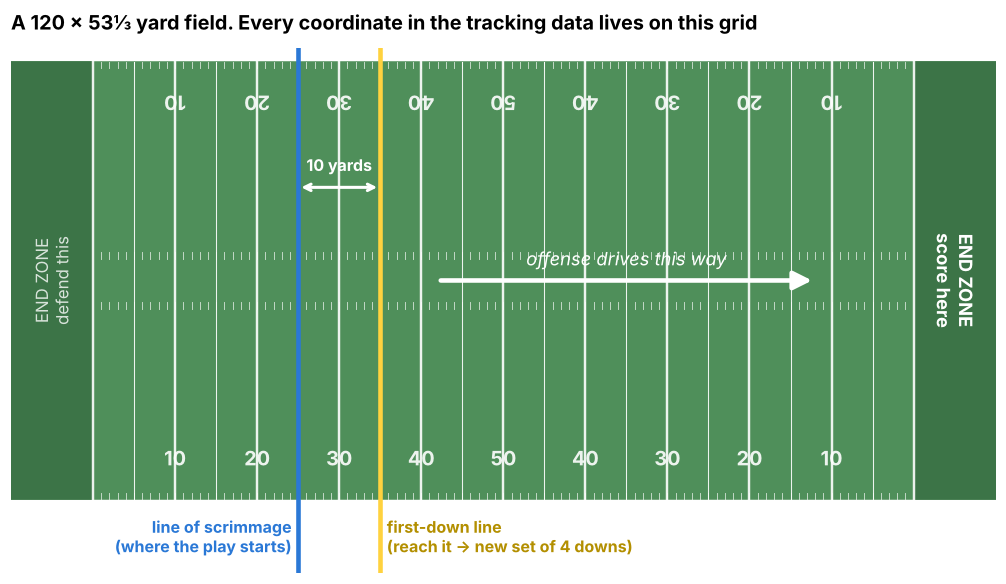

In [3]:
FIELD_GREEN, ENDZONE = "#4f8f5a", "#3c7447"


def draw_field(ax, x_min=0, x_max=120, numbers=True):
    """A to-scale NFL field: 120 x 53.3 yards, end zones from 0-10 and 110-120."""
    ax.add_patch(Rectangle((0, 0), 120, 53.3, color=FIELD_GREEN, zorder=0))
    for x0 in (0, 110):
        ax.add_patch(Rectangle((x0, 0), 10, 53.3, color=ENDZONE, zorder=0))
    for x in range(10, 111, 5):
        ax.plot([x, x], [0, 53.3], color="white", lw=1.6 if x % 10 == 0 else 0.7, alpha=0.9, zorder=1)
    for x in range(11, 110):
        for y in (0.4, 23.6, 29.7, 52.9):
            ax.plot([x, x], [y - 0.4, y + 0.4], color="white", lw=0.6, alpha=0.7, zorder=1)
    if numbers:
        for x in range(20, 101, 10):
            label = str(x - 10 if x <= 60 else 110 - x)
            for y, rot in ((5, 0), (48.3, 180)):
                ax.text(x, y, label, color="white", ha="center", va="center", fontsize=13,
                        fontweight="bold", rotation=rot, alpha=0.9, zorder=1)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-1, 54.3)
    ax.set_aspect("equal")
    ax.axis("off")


fig, ax = plt.subplots(figsize=(13, 6.2))
draw_field(ax)
los, first_down = 35, 45
ax.axvline(los, color="#2a78d6", lw=3, zorder=3)
ax.axvline(first_down, color="#ffd23f", lw=3, zorder=3)
ax.annotate("", xy=(first_down, 38), xytext=(los, 38),
            arrowprops=dict(arrowstyle="<->", color="white", lw=2), zorder=4)
ax.text((los + first_down) / 2, 40, "10 yards", color="white", ha="center", fontweight="bold", zorder=4)
ax.annotate("", xy=(98, 26.65), xytext=(52, 26.65),
            arrowprops=dict(arrowstyle="-|>", color="white", lw=3, mutation_scale=25), zorder=4)
ax.text(75, 28.5, "offense drives this way", color="white", ha="center", fontsize=12, style="italic", zorder=4)
ax.text(los - 0.8, -2.2, "line of scrimmage\n(where the play starts)", color="#2a78d6", ha="right", va="top", fontweight="bold")
ax.text(first_down + 0.8, -2.2, "first-down line\n(reach it → new set of 4 downs)", color="#b38f00", ha="left", va="top", fontweight="bold")
ax.text(115, 26.65, "END ZONE\nscore here", color="white", ha="center", va="center", rotation=270, fontweight="bold", fontsize=12)
ax.text(5, 26.65, "END ZONE\ndefend this", color="white", ha="center", va="center", rotation=90, fontsize=11, alpha=0.8)
ax.set_ylim(-9, 55)
ax.set_title("A 120 × 53⅓ yard field. Every coordinate in the tracking data lives on this grid", pad=12)
plt.show()

### How do you score?

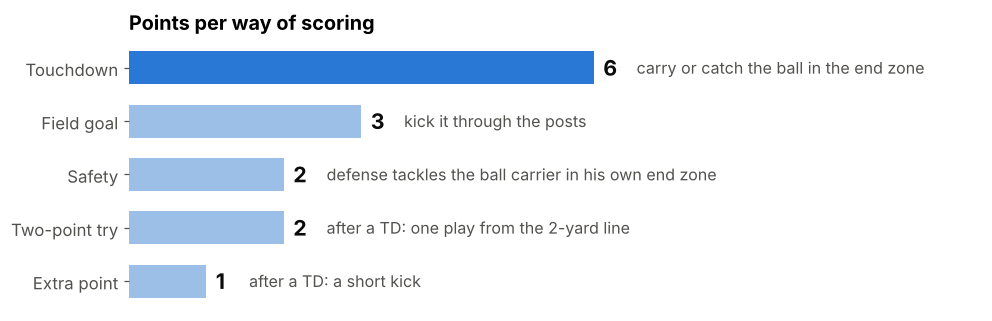

In [4]:
scores = [("Touchdown", 6, "carry or catch the ball in the end zone"),
          ("Field goal", 3, "kick it through the posts"),
          ("Safety", 2, "defense tackles the ball carrier in his own end zone"),
          ("Two-point try", 2, "after a TD: one play from the 2-yard line"),
          ("Extra point", 1, "after a TD: a short kick")]
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, (label, pts, how) in enumerate(scores):
    y = len(scores) - 1 - i
    ax.barh(y, pts, color="#2a78d6" if pts == 6 else "#9cbfe8", height=0.62)
    ax.text(pts + 0.12, y, f"{pts}  ", va="center", fontsize=14, fontweight="bold", color=INK)
    ax.text(pts + 0.55, y, how, va="center", color=MUTED)
ax.set_yticks(range(len(scores)), [s[0] for s in scores][::-1], fontsize=11)
ax.set_xlim(0, 11)
ax.set_xticks([])
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Points per way of scoring")
plt.show()

### A real drive, play by play
Here's a touchdown drive picked straight out of `player_play.csv`. Each arrow is one play. Watch the **down** counter reset every time the offense passes the yellow line.

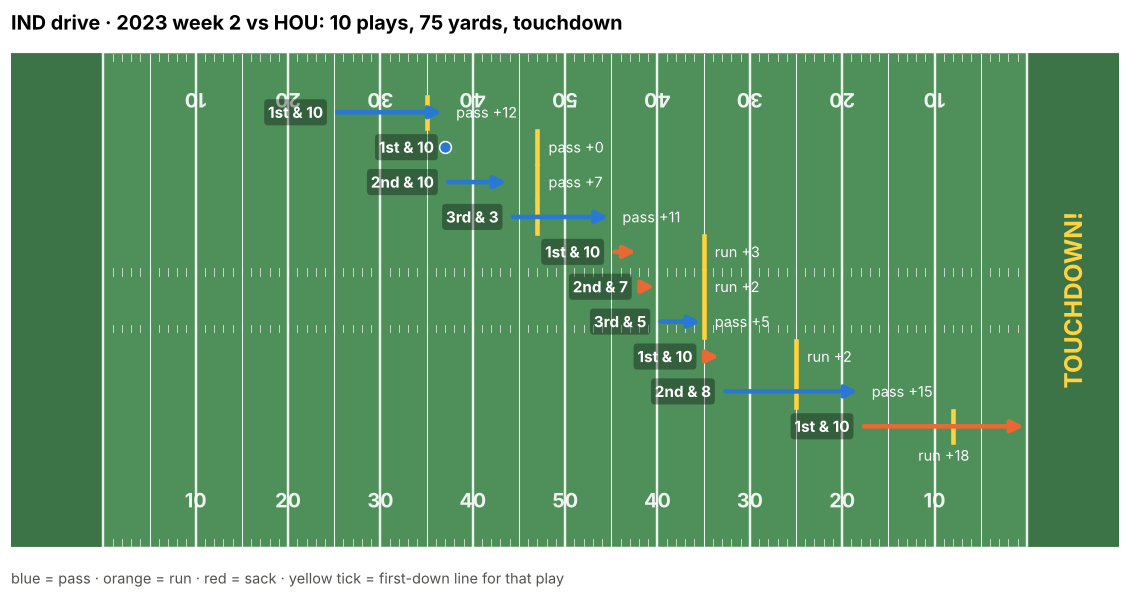

In [5]:
def yards_to_goal(df: pl.DataFrame) -> pl.DataFrame:
    """yardline_100 = yards left to the opponent's end zone."""
    return df.with_columns(
        yl100=pl.when(pl.col("yardline_side") == pl.col("possession_team"))
        .then(100 - pl.col("yardline_number")).otherwise(pl.col("yardline_number")))


plays_once = (yards_to_goal(player_play.unique(["game_id", "play_id"]))
              .join(games, on="game_id").filter(pl.col("season_type") == "REG")
              .sort("game_id", "play_id"))
plays_once = plays_once.with_columns(
    drive=(pl.col("possession_team") != pl.col("possession_team").shift(1).over("game_id")).fill_null(True).cum_sum())
plays_once = plays_once.with_columns(next_yl=pl.col("yl100").shift(-1).over("drive"))

# A complete drive: 9+ plays from deep in its own half to a TD, no missing plays in between
drives = (plays_once.group_by("drive").agg(
    n=pl.len(), start=pl.col("yl100").first(), quarters=pl.col("quarter").n_unique(),
    td=pl.col("play_description").last().str.contains("TOUCHDOWN"),
    third_down=(pl.col("down") == 3).any(), passes=pl.col("pass_result").is_in(["C", "I", "IN", "S"]).sum(),
    gap=(pl.col("yl100") - pl.col("yards_gained") - pl.col("next_yl")).abs().fill_null(0).max(),
    game_id=pl.col("game_id").first(), first_play=pl.col("play_id").first())
    .filter(pl.col("td") & (pl.col("gap") < 0.5) & pl.col("n").is_between(9, 11) & (pl.col("start") >= 75)
            & (pl.col("quarters") == 1) & pl.col("third_down") & pl.col("passes").is_between(3, 6))
    .sort("game_id", "first_play"))
drive = plays_once.filter(pl.col("drive") == drives["drive"][0]).to_pandas()

fig, ax = plt.subplots(figsize=(13, 7))
draw_field(ax)
n = len(drive)
lane = np.linspace(47, 13, n)
for i, r in drive.iterrows():
    x0 = 110 - r.yl100                 # offense drives toward x = 110
    x1 = x0 + r.yards_gained
    first_line = min(x0 + r.yards_to_go, 110)
    ax.plot([first_line, first_line], [lane[i] - 1.7, lane[i] + 1.7], color="#ffd23f", lw=3, zorder=3)
    kind = {"C": "pass", "I": "pass", "IN": "pass", "S": "sack", "R": "QB run"}.get(r.pass_result, "run")
    color = {"pass": "#2a78d6", "run": "#eb6834", "QB run": "#eb6834", "sack": "#e34948"}[kind]
    if abs(r.yards_gained) < 0.5:
        ax.scatter(x0, lane[i], s=60, color=color, edgecolor="white", zorder=4)
    else:
        ax.annotate("", xy=(x1, lane[i]), xytext=(x0, lane[i]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=3, mutation_scale=16), zorder=4)
    label = f"{['', '1st', '2nd', '3rd', '4th'][r.down]} & {r.yards_to_go}"
    ax.text(min(x0, x1) - 1.2, lane[i], label, ha="right", va="center", color="white", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc="#00000055", ec="none"), zorder=5)
    result = f"{kind} {r.yards_gained:+.0f}" + ("  TOUCHDOWN!" if "TOUCHDOWN" in r.play_description else "")
    if x1 > 100:   # the scoring play: result under the arrow, TOUCHDOWN in the end zone
        ax.text((x0 + x1) / 2, lane[i] - 2.2, result.replace("  TOUCHDOWN!", ""), ha="center", va="top",
                color="white", fontsize=9.5, zorder=5)
        ax.text(115, 26.65, "TOUCHDOWN!", rotation=90, ha="center", va="center", color="#ffd23f",
                fontsize=16, fontweight="bold", zorder=5)
    else:
        ax.text(max(x0, x1, first_line) + 1.2, lane[i], result, ha="left", va="center", color="white",
                fontsize=9.5, zorder=5)
g0 = drive.iloc[0]
ax.set_title(f"{g0.possession_team} drive · {g0.season} week {g0.week} vs "
             f"{g0.visitor_team_abbr if g0.possession_team == g0.home_team_abbr else g0.home_team_abbr}: "
             f"{n} plays, {drive.yards_gained.sum():.0f} yards, touchdown", pad=10)
ax.text(0, -2.5, "blue = pass · orange = run · red = sack · yellow tick = first-down line for that play",
        color=MUTED, fontsize=9.5, va="top")
plt.show()

> 💡 **In the data:** `down`, `yards_to_go`, `yardline_side/number`, `yards_gained` and `play_description` live in `player_play.csv`.
> One row per **player per play**, so de-duplicate on `(game_id, play_id)` when you want plays.

---
## 2 · Who's on the field?

Every play is 11 vs 11. Each player has a specialised job, and that shapes the **body type** and **skills** you'd look for at the Combine.
Only **5 position groups** have Combine tracking in this competition (coloured below). QBs, RBs and LBs are greyed out.

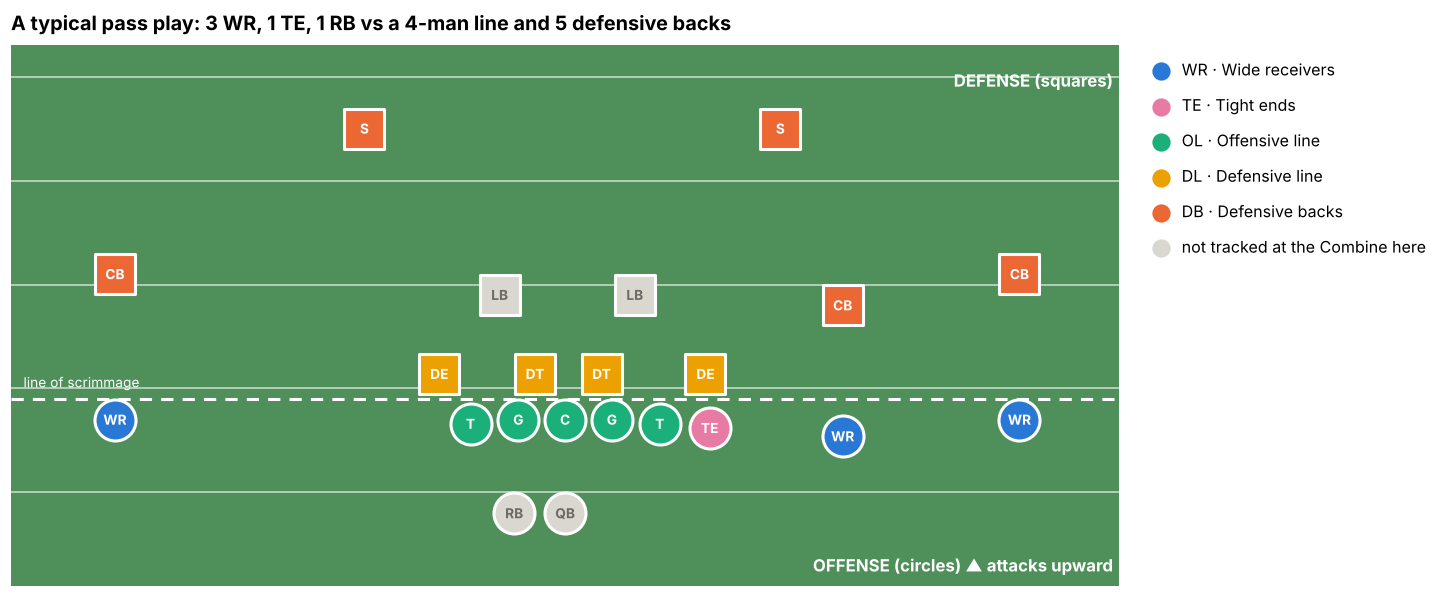

In [6]:
# (label, across-field position, yards from the line of scrimmage, group). Offense attacks upward.
OFFENSE = [
    ("C", 26.65, -1, "OL"), ("G", 24.4, -1, "OL"), ("G", 28.9, -1, "OL"), ("T", 22.1, -1.2, "OL"), ("T", 31.2, -1.2, "OL"),
    ("TE", 33.6, -1.4, "TE"), ("QB", 26.65, -5.5, None), ("RB", 24.2, -5.5, None),
    ("WR", 5, -1, "WR"), ("WR", 40, -1.8, "WR"), ("WR", 48.5, -1, "WR")]
DEFENSE = [
    ("DE", 20.6, 1.2, "DL"), ("DT", 25.2, 1.2, "DL"), ("DT", 28.4, 1.2, "DL"), ("DE", 33.4, 1.2, "DL"),
    ("LB", 23.5, 5, None), ("LB", 30, 5, None),
    ("CB", 5, 6, "DB"), ("CB", 40, 4.5, "DB"), ("CB", 48.5, 6, "DB"), ("S", 17, 13, "DB"), ("S", 37, 13, "DB")]

fig, ax = plt.subplots(figsize=(13, 7.4))
ax.add_patch(Rectangle((0, -9), 53.3, 26, color=FIELD_GREEN, zorder=0))
for yl in range(-5, 16, 5):
    ax.plot([0, 53.3], [yl + 0.5, yl + 0.5], color="white", lw=1.2, alpha=0.6, zorder=1)
ax.plot([0, 53.3], [0, 0], color="white", lw=2, ls=(0, (4, 3)), zorder=2)
ax.text(0.6, 0.4, "line of scrimmage", color="white", fontsize=9, va="bottom")
for team, marker in ((OFFENSE, "o"), (DEFENSE, "s")):
    for label, x, y, grp in team:
        ax.scatter(x, y, s=720, color=POS_COLORS.get(grp, "#d9d7d0"), marker=marker, edgecolor="white", linewidth=2, zorder=4)
        ax.text(x, y, label, ha="center", va="center", fontsize=9, fontweight="bold",
                color="white" if grp else "#6b6a65", zorder=5)
ax.text(53, -8.3, "OFFENSE (circles) ▲ attacks upward", color="white", ha="right", fontsize=11, fontweight="bold")
ax.text(53, 15.8, "DEFENSE (squares)", color="white", ha="right", fontsize=11, fontweight="bold", va="top")
for g in POS_ORDER:
    ax.scatter([], [], s=120, color=POS_COLORS[g], label=f"{g} · {POS_NAMES[g]}")
ax.scatter([], [], s=120, color="#d9d7d0", label="not tracked at the Combine here")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=10.5, handletextpad=0.3, labelspacing=1)
ax.set_xlim(0, 53.3)
ax.set_ylim(-9, 17)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("A typical pass play: 3 WR, 1 TE, 1 RB vs a 4-man line and 5 defensive backs", pad=10)
plt.show()

| Group | Job in one line | Combine "superpower" | What the game data measures |
|---|---|---|---|
| 🔵 **WR** wide receiver | Run routes, get open, catch | Speed, sharp cuts, hands | `separation_at_pass_forward`, `route_ran`, targets |
| 🩷 **TE** tight end | Half blocker, half receiver | Size + speed combo | separation, routes run |
| 🟢 **OL** offensive line | Wall in front of the QB | Strength, quick feet, balance | `pressure_allowed`, `sack_allowed`, time to pressure allowed |
| 🟡 **DL** defensive line | Smash through the wall to the QB | Explosive first step, bend | `player_get_off`, `time_to_pressure`, sacks |
| 🟠 **DB** cornerback / safety | Shadow receivers, stop the pass | Backpedal, flip hips, burst | `coverage_assignment`, tackles, in-game tracking |

---
## 3 · Meet the rookies
The dataset follows **one cohort**: every player from the 2023, 2024 and 2025 draft classes who was tracked at the Combine, plus how their NFL careers went.

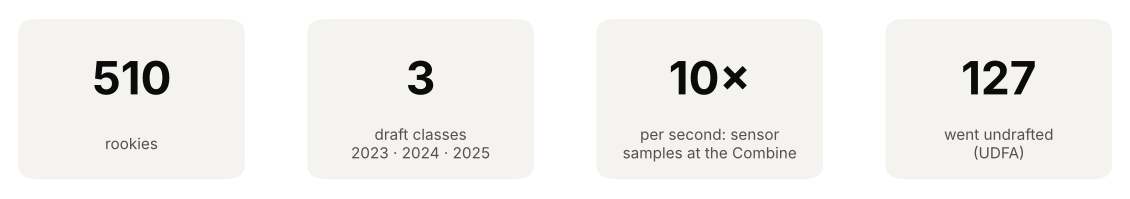

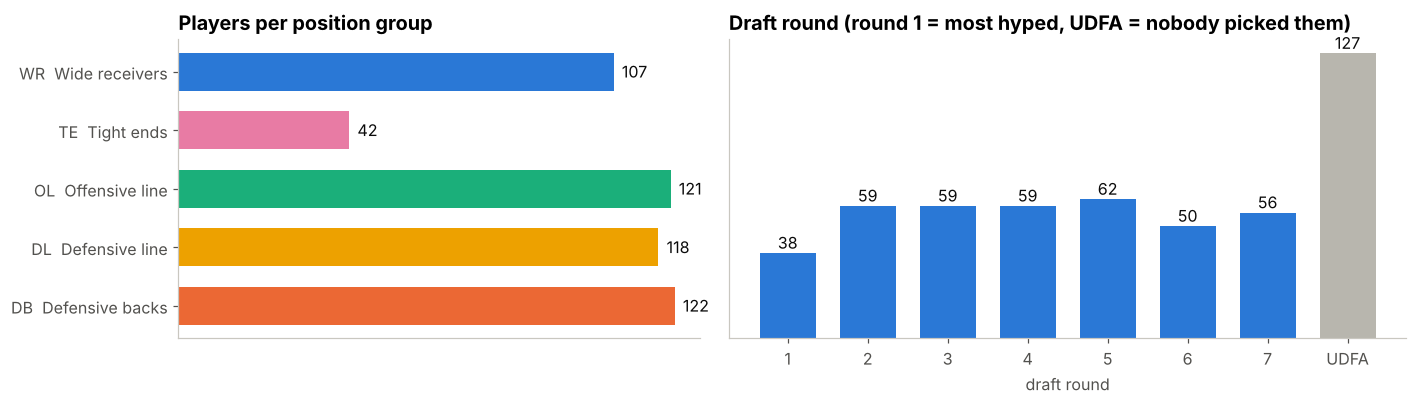

In [7]:
cohort = (players.join(combine.select(pl.exclude("draft_year")), on="nfl_id")
          .join(career, on="nfl_id", how="left")
          .rename({"combine_position": "pos"}))

tiles = [(f"{cohort.height}", "rookies"), ("3", "draft classes\n2023 · 2024 · 2025"),
         ("10×", "per second: sensor\nsamples at the Combine"),
         (f"{(cohort['draft_round'].is_null()).sum()}", "went undrafted\n(UDFA)")]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.1))
for ax, (big, small) in zip(axes, tiles):
    ax.add_patch(FancyBboxPatch((0.03, 0.05), 0.94, 0.9, boxstyle="round,pad=0,rounding_size=0.08",
                                fc="#f4f3ef", ec="none", transform=ax.transAxes))
    ax.text(0.5, 0.62, big, ha="center", va="center", fontsize=30, fontweight="bold", color=INK, transform=ax.transAxes)
    ax.text(0.5, 0.25, small, ha="center", va="center", fontsize=10, color=MUTED, transform=ax.transAxes)
    ax.axis("off")
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
counts = cohort.group_by("pos").len().to_pandas().set_index("pos").loc[POS_ORDER[::-1]]
a1.barh(counts.index, counts["len"], color=[POS_COLORS[p] for p in counts.index], height=0.65)
for y, v in enumerate(counts["len"]):
    a1.text(v + 2, y, v, va="center", color=INK)
a1.set_yticks(range(5), [f"{p}  {POS_NAMES[p]}" for p in counts.index])
a1.set_title("Players per position group")
a1.grid(axis="y", visible=False)
a1.set_xticks([])

rounds = (cohort.with_columns(r=pl.col("draft_round").cast(pl.String).fill_null("UDFA"))
          .group_by("r").len().to_pandas().set_index("r").reindex([*map(str, range(1, 8)), "UDFA"]).fillna(0))
a2.bar(rounds.index, rounds["len"], color=["#2a78d6"] * 7 + [GREY], width=0.7)
for x, v in enumerate(rounds["len"]):
    a2.text(x, v + 2, int(v), ha="center", color=INK)
a2.set_title("Draft round (round 1 = most hyped, UDFA = nobody picked them)")
a2.set_xlabel("draft round")
a2.set_yticks([])
a2.grid(False)
plt.tight_layout()
plt.show()

### Built for the job
Each dot is one rookie, measured at the Combine. Positions basically sort themselves by body type: big linemen up top, lean receivers and DBs bottom-left.

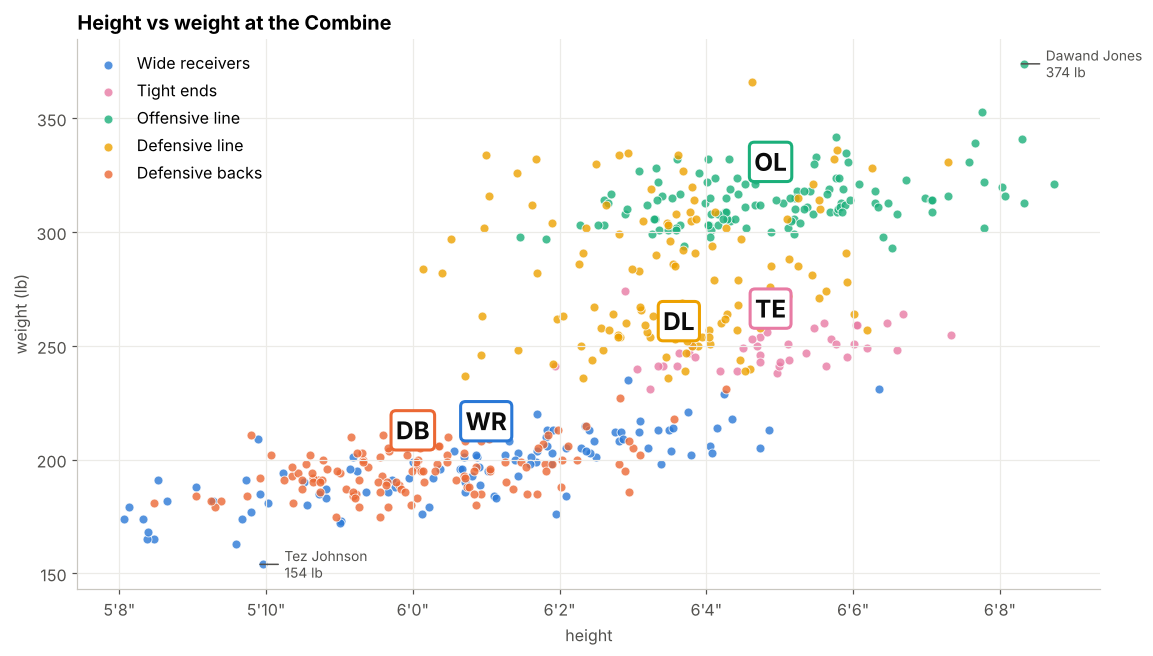

In [8]:
fig, ax = plt.subplots(figsize=(12, 6.5))
cb = cohort.filter(pl.col("combine_height").is_not_null() & pl.col("combine_weight").is_not_null()).to_pandas()
rng = np.random.default_rng(7)
for p in POS_ORDER:
    d = cb[cb.pos == p]
    ax.scatter(d.combine_height + rng.uniform(-0.12, 0.12, len(d)), d.combine_weight, s=34, color=POS_COLORS[p],
               alpha=0.8, edgecolor="white", linewidth=0.6, label=POS_NAMES[p])
    ax.text(d.combine_height.median(), d.combine_weight.median() + (14 if p != "DL" else -22), p, fontsize=16,
            fontweight="bold", color=INK, ha="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=POS_COLORS[p], lw=2))
for _, r in pd.concat([cb.nlargest(1, "combine_weight"), cb.nsmallest(1, "combine_weight")]).iterrows():
    ax.annotate(f"{r.display_name}\n{r.combine_weight:.0f} lb", (r.combine_height, r.combine_weight),
                xytext=(18, 0), textcoords="offset points", fontsize=9, color=MUTED, va="center",
                arrowprops=dict(arrowstyle="-", color=MUTED))
ticks = range(68, 82, 2)
ax.set_xticks(ticks, [f"{t // 12}'{t % 12}\"" for t in ticks])
ax.set_xlabel("height")
ax.set_ylabel("weight (lb)")
ax.legend(loc="upper left", ncol=1)
ax.set_title("Height vs weight at the Combine")
plt.show()

---
## 4 · The Combine: a job interview with sensors

Every February, ~300 top college prospects go to Indianapolis and run the same drills in front of all 32 teams.
Teams traditionally keep the **stopwatch** results (`combine_results.csv`). This year we also get the **10 Hz tracking**:
an (x, y) position, speed `s` and acceleration `a` every 0.1 s (`combine_tracking.csv`).

### What "10 Hz" looks like
One dot = one tenth of a second in the fastest 40-yard dash in the data. Dots spreading apart = he's speeding up.

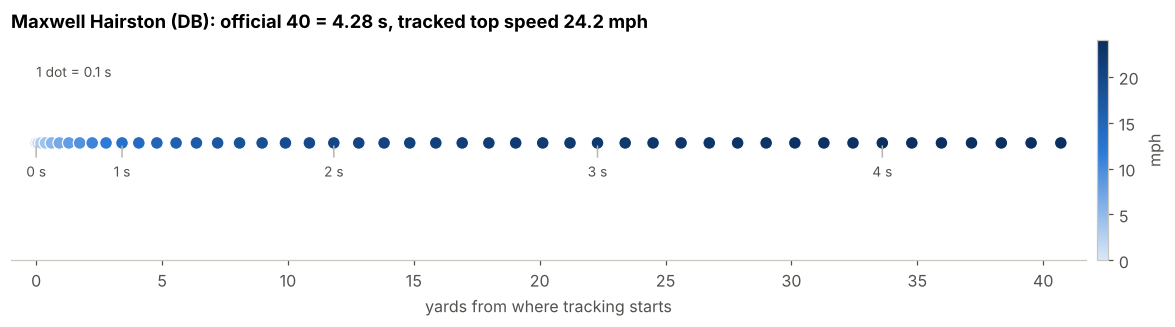

In [9]:
forty = tracking.filter(pl.col("drill_name") == "FORTY_YARD_DASH").with_columns(
    dist=pl.col("step").cum_sum().over("event_id"))
fastest = (forty.group_by("event_id").agg(pl.col("s").max().alias("top"), pl.col("nfl_id").first(), pl.col("pos").first())
           .sort("top", descending=True).row(0, named=True))
rep = forty.filter(pl.col("event_id") == fastest["event_id"]).to_pandas()
off = combine.filter(pl.col("nfl_id") == fastest["nfl_id"]).row(0, named=True)

fig, ax = plt.subplots(figsize=(13, 2.6))
sc = ax.scatter(rep.dist, np.zeros(len(rep)), c=rep.s * YDS_TO_MPH, cmap=BLUES_DOTS, vmin=0, vmax=24, s=70,
                edgecolor="white", lw=0.8, zorder=3)
for i in range(0, len(rep), 10):
    ax.annotate(f"{rep.t[i]:.0f} s", (rep.dist[i], 0), xytext=(0, -22), textcoords="offset points",
                ha="center", color=MUTED, fontsize=9, arrowprops=dict(arrowstyle="-", color=GREY))
ax.text(0, 0.9, "1 dot = 0.1 s", color=MUTED, fontsize=9)
ax.set_ylim(-1.6, 1.4)
ax.set_xlim(-1, rep.dist.max() + 1)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("yards from where tracking starts")
plt.colorbar(sc, ax=ax, fraction=0.02, pad=0.01, label="mph")
ax.set_title(f"{names[fastest['nfl_id']]} ({fastest['pos']}): official 40 = {off['forty']} s, "
             f"tracked top speed {fastest['top'] * YDS_TO_MPH:.1f} mph", fontsize=12, pad=8)
plt.show()

### How fast does each position run?
Speed at every yard of the 40, median across all players of a group. Receivers and DBs top out around 22 mph; 310-lb offensive linemen still hit ~19.

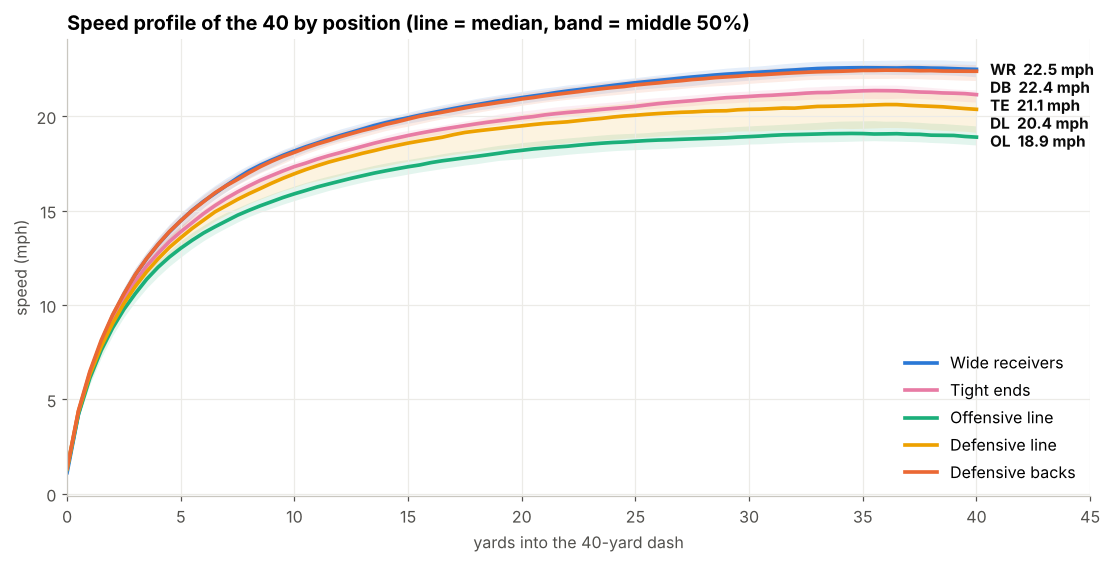

In [10]:
grid = np.arange(0, 40.5, 0.5)
curves = []
for (eid,), d in forty.select("event_id", "pos", "dist", "s").group_by("event_id"):
    d = d.sort("dist")
    if d["dist"].max() < 38:
        continue
    curves.append((d["pos"][0], np.interp(grid, d["dist"].to_numpy(), d["s"].to_numpy())))

fig, ax = plt.subplots(figsize=(12, 5.4))
ends, ends_y = [], []
for p in POS_ORDER:
    arr = np.array([c for g, c in curves if g == p]) * YDS_TO_MPH
    lo, mid, hi = np.percentile(arr, [25, 50, 75], axis=0)
    ax.fill_between(grid, lo, hi, color=POS_COLORS[p], alpha=0.12, lw=0)
    ax.plot(grid, mid, color=POS_COLORS[p], lw=2.4, label=POS_NAMES[p])
    ends.append((mid[-1], p))
for i, (v, p) in enumerate(sorted(ends, reverse=True)):   # nudge end labels apart
    y = min(v, ends_y[-1] - 0.95) if ends_y else v
    ends_y.append(y)
    ax.text(40.6, y, f"{p}  {v:.1f} mph", color=INK, va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, 45)
ax.set_xlabel("yards into the 40-yard dash")
ax.set_ylabel("speed (mph)")
ax.set_title("Speed profile of the 40 by position (line = median, band = middle 50%)")
ax.legend(loc="lower right", ncol=1)
plt.show()

### 🏁 Race time
The fastest 40 of each position group, side by side. Press ▶.

In [11]:
racers = []
for p in POS_ORDER:
    best = (forty.filter(pl.col("pos") == p).group_by("event_id")
            .agg(pl.col("s").max().alias("top"), pl.col("nfl_id").first()).sort("top", descending=True).row(0, named=True))
    d = forty.filter(pl.col("event_id") == best["event_id"]).select("t", "dist", "s").to_pandas()
    racers.append((p, names[best["nfl_id"]], d))

T = np.round(np.arange(0, min(d.t.max() for *_, d in racers), 0.1), 1)
lanes = {p: i for i, p in enumerate(POS_ORDER[::-1])}


def race_frame(t):
    xs = [np.interp(t, d.t, d.dist) for *_, d in racers]
    return go.Scatter(x=xs, y=[lanes[p] for p, *_ in racers], mode="markers+text",
                      marker=dict(size=26, color=[POS_COLORS[p] for p, *_ in racers], line=dict(color="white", width=2)),
                      text=[p for p, *_ in racers], textfont=dict(color="white", size=10), hoverinfo="skip")


race = go.Figure(
    data=[race_frame(0)],
    frames=[go.Frame(data=[race_frame(t)], name=str(t)) for t in T],
    layout=go.Layout(
        title="Fastest 40-yard dash per position group (tracked, 10 Hz)",
        xaxis=dict(range=[-1, 42], title="yards", dtick=10, gridcolor="#ecebe7", zeroline=False),
        yaxis=dict(tickvals=list(lanes.values()), ticktext=[f"{p} · {n}" for p, n, _ in racers[::-1]],
                   range=[-0.7, 4.7], showgrid=False),
        plot_bgcolor="#f4f3ef", paper_bgcolor="white", height=380, margin=dict(l=190, r=30, t=60, b=40),
        shapes=[dict(type="line", x0=40, x1=40, y0=-0.7, y1=4.7, line=dict(color="#e34948", width=3))],
        updatemenus=[dict(type="buttons", x=0, y=-0.18, xanchor="left", showactive=False, buttons=[
            dict(label="▶ Run", method="animate",
                 args=[None, dict(frame=dict(duration=100, redraw=False), fromcurrent=True, transition=dict(duration=0))]),
            dict(label="↺ Reset", method="animate", args=[[str(T[0])], dict(mode="immediate", frame=dict(duration=0))])])],
    ),
)
race.show()

### The drill gallery
Besides the 40, every position runs its own **position drills**, designed to mimic what they do in games.
Each panel below shows one drill: **grey lines** are many players' reps, the **coloured line** is one typical rep (darker = faster), ● marks the start.

In [12]:
DRILL_NOTES = {
    "FORTY_YARD_DASH": "straight 40-yd sprint",
    "THREE_CONE_DRILL": "L-shaped run around 3 cones",
    "SHORT_SHUTTLE": "5-10-5: sprint, turn, sprint, turn",
    "GAUNTLET_DRILL": "run across the field catching balls from both sides",
    "GO_ROUTE_RIGHT": "sprint straight downfield",
    "SLANT_ROUTE_LEFT": "quick diagonal cut inside",
    "CURL_ROUTE_RIGHT": "run, stop and turn back to the QB",
    "COMEBACK_ROUTE_RIGHT": "run deep, break back to the sideline",
    "POST_CORNER_ROUTE_RIGHT": "fake to the middle, break to the corner",
    "DAGGER_ROUTE_LEFT": "deep in-breaking route",
    "OVER_SHOULDER_ADJUST": "track a ball over the shoulder",
    "RED_ZONE_FADE_RIGHT": "fade to the back corner of the end zone",
    "PASS_RUSH_DRILL": "beat 2 dummies with a rip or swim, finish at a cone",
    "FOUR_BAG_AGILITY_DRILL": "weave and step over bags",
    "BODY_CONTROL_DRILL": "run, bend and change direction around bags",
    "PASS_PRO_MIRROR_DRILL": "slide to mirror a partner side to side",
    "PASS_RUSH_DROP": "drop back in pass-protection steps",
    "OL_PULL_DRILL_FOLD_BLOCK_RIGHT": "leave the line and run to a new block",
    "BACK_PEDAL_AND_90_DEGREE_BREAK_DRILL": "backpedal, then break sideways",
    "W_DRILL": "backpedal in a zig-zag W",
    "BOX_DRILL": "sprint, shuffle, backpedal around a square",
    "BLOCK_EXPLOSION": "explode out of a stance into a block",
}
BLUES = LinearSegmentedColormap.from_list("speed", ["#c6dbf5", "#2a78d6", "#0b2f5e"])


def rotate_to_first_move(xy: np.ndarray) -> np.ndarray:
    """Put the start at (0, 0) and turn the path so its opening stretch points up."""
    xy = xy - xy[0]
    arc = np.r_[0, np.cumsum(np.hypot(*np.diff(xy, axis=0).T))]
    k = max(1, int(np.searchsorted(arc, min(5, 0.2 * arc[-1]))))
    ang = np.arctan2(xy[k, 1], xy[k, 0]) - np.pi / 2
    rot = np.array([[np.cos(-ang), -np.sin(-ang)], [np.sin(-ang), np.cos(-ang)]])
    return xy @ rot.T


def resample(xy: np.ndarray, n=60) -> np.ndarray:
    """n points evenly spaced along the path (so reps of different length can be compared)."""
    d = np.r_[0, np.cumsum(np.hypot(*np.diff(xy, axis=0).T))]
    u = np.linspace(0, d[-1], n)
    return np.c_[np.interp(u, d, xy[:, 0]), np.interp(u, d, xy[:, 1])]


def align_to(ref: np.ndarray, xy: np.ndarray) -> np.ndarray:
    """Rotate (and mirror if needed) a rep so it best overlaps the reference rep: 2-D Procrustes."""
    xy = xy - xy[0]
    a, b = resample(ref), resample(xy)
    best, err = xy, np.inf
    for flip in (1, -1):
        bf = b * [1, flip]
        u, _, vt = np.linalg.svd(bf.T @ a)
        r = u @ vt
        if np.linalg.det(r) < 0:                     # keep it a pure rotation
            u[:, -1] *= -1
            r = u @ vt
        e = np.sum((bf @ r - a) ** 2)
        if e < err:
            best, err = (xy * [1, flip]) @ r, e
    return best


def drill_panel(ax, reps: pl.DataFrame, drill: str, color: str, n_ghosts=45):
    d = reps.filter(pl.col("drill_name") == drill)
    ids = d.group_by("event_id").agg(pl.col("t").max()).sort("t", "event_id")["event_id"].to_list()
    paths = {k[0]: g for k, g in d.group_by("event_id")}
    one = paths[ids[len(ids) // 2]]                          # the rep with the median duration
    ref = rotate_to_first_move(one.select("x", "y").to_numpy())
    for eid in ids[:: max(1, len(ids) // n_ghosts)]:
        xy = align_to(ref, paths[eid].select("x", "y").to_numpy())
        ax.plot(*xy.T, color=GREY, lw=0.7, alpha=0.45)
    lc = LineCollection(np.stack([ref[:-1], ref[1:]], axis=1), cmap=BLUES, norm=plt.Normalize(0, 10),
                        lw=3, capstyle="round")
    lc.set_array(one["s"].to_numpy()[1:])
    ax.add_collection(lc)
    ax.scatter(0, 0, s=70, color=color, edgecolor="white", lw=1.5, zorder=5)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)
    title = drill.replace("_DRILL", "").replace("_", " ").title().replace("Ol ", "OL ")
    title = textwrap.shorten(title, 34, placeholder="…")
    ax.set_title(f"{title}\n", fontsize=10.5, loc="center")
    ax.text(0.5, 1.0, f"{DRILL_NOTES.get(drill, '')}  ({len(ids)} reps · {one['t'].max():.1f}s)",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=8, color=MUTED)


SHARED = ["FORTY_YARD_DASH", "THREE_CONE_DRILL", "SHORT_SHUTTLE"]


def drill_gallery(pos=None, n_max=8):
    reps = tracking if pos is None else tracking.filter(pl.col("pos") == pos)
    reps = reps.filter(pl.col("drill_name").is_in(SHARED) == (pos is None))
    top = (reps.group_by("drill_name").agg(pl.col("event_id").n_unique().alias("n"))
           .filter(pl.col("n") >= 15).sort("n", "drill_name", descending=True).head(n_max)["drill_name"].to_list())
    cols = 4 if pos else 3
    rows = int(np.ceil(len(top) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.7 * rows if pos else 4.2))
    color = POS_COLORS.get(pos, INK)
    for ax, drill in zip(np.ravel(axes), top):
        drill_panel(ax, reps, drill, color)
    for ax in np.ravel(axes)[len(top):]:
        ax.axis("off")
    fig.suptitle(f"{POS_NAMES[pos]} ({pos}) drills" if pos else "Drills everyone runs", x=0.01, ha="left",
                 fontsize=15, fontweight="bold", color=color)
    plt.tight_layout()
    plt.show()

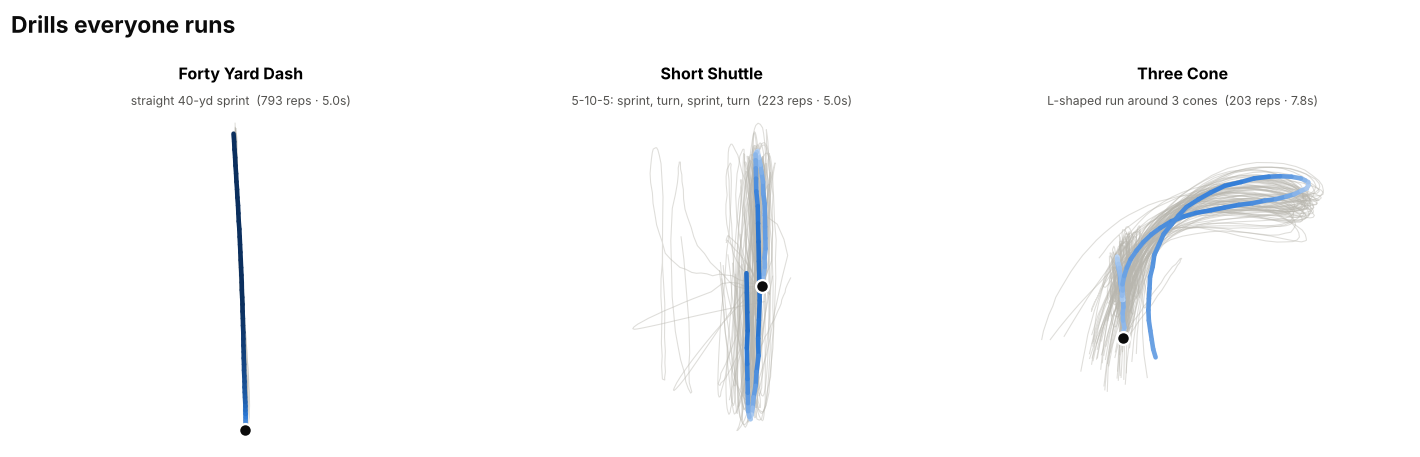

In [13]:
drill_gallery()

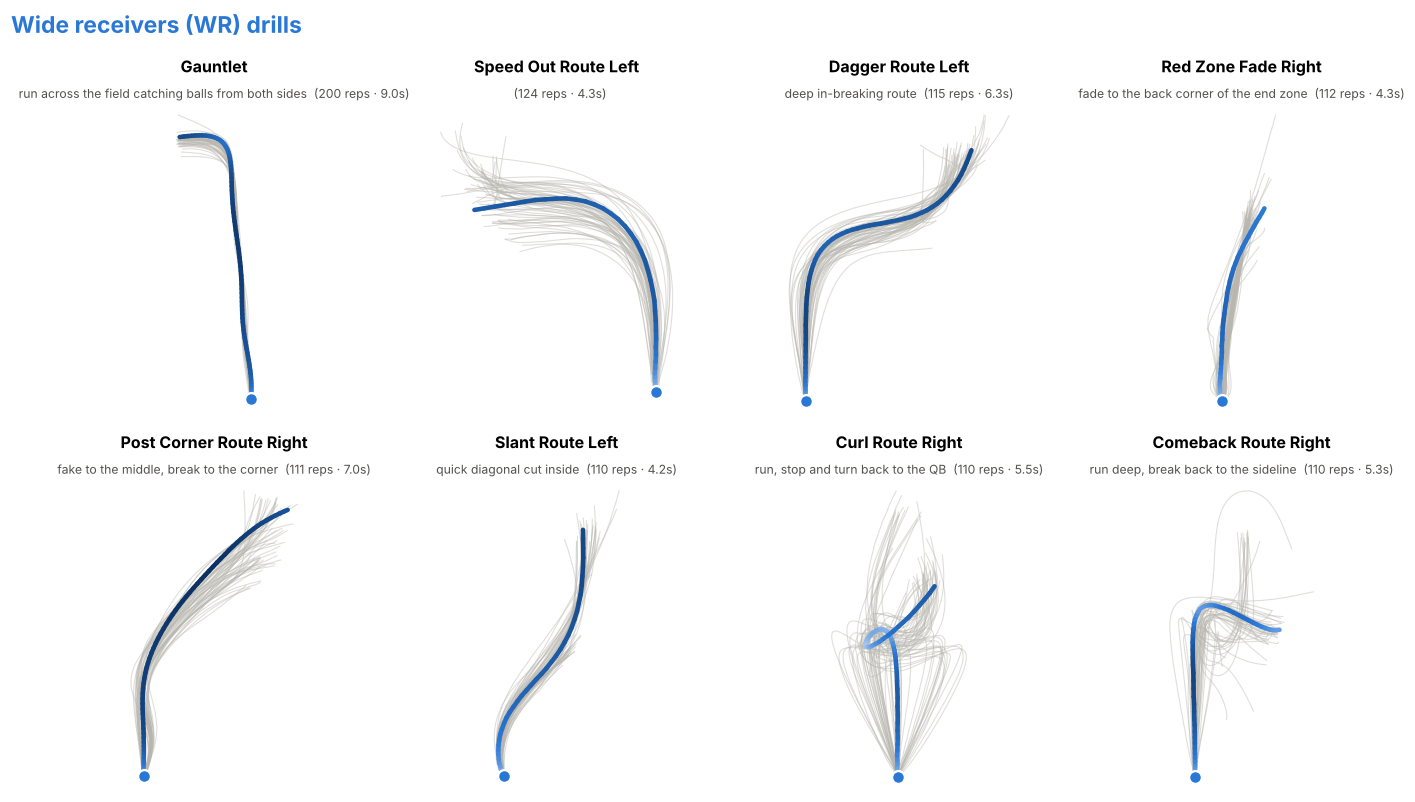

In [14]:
drill_gallery("WR")

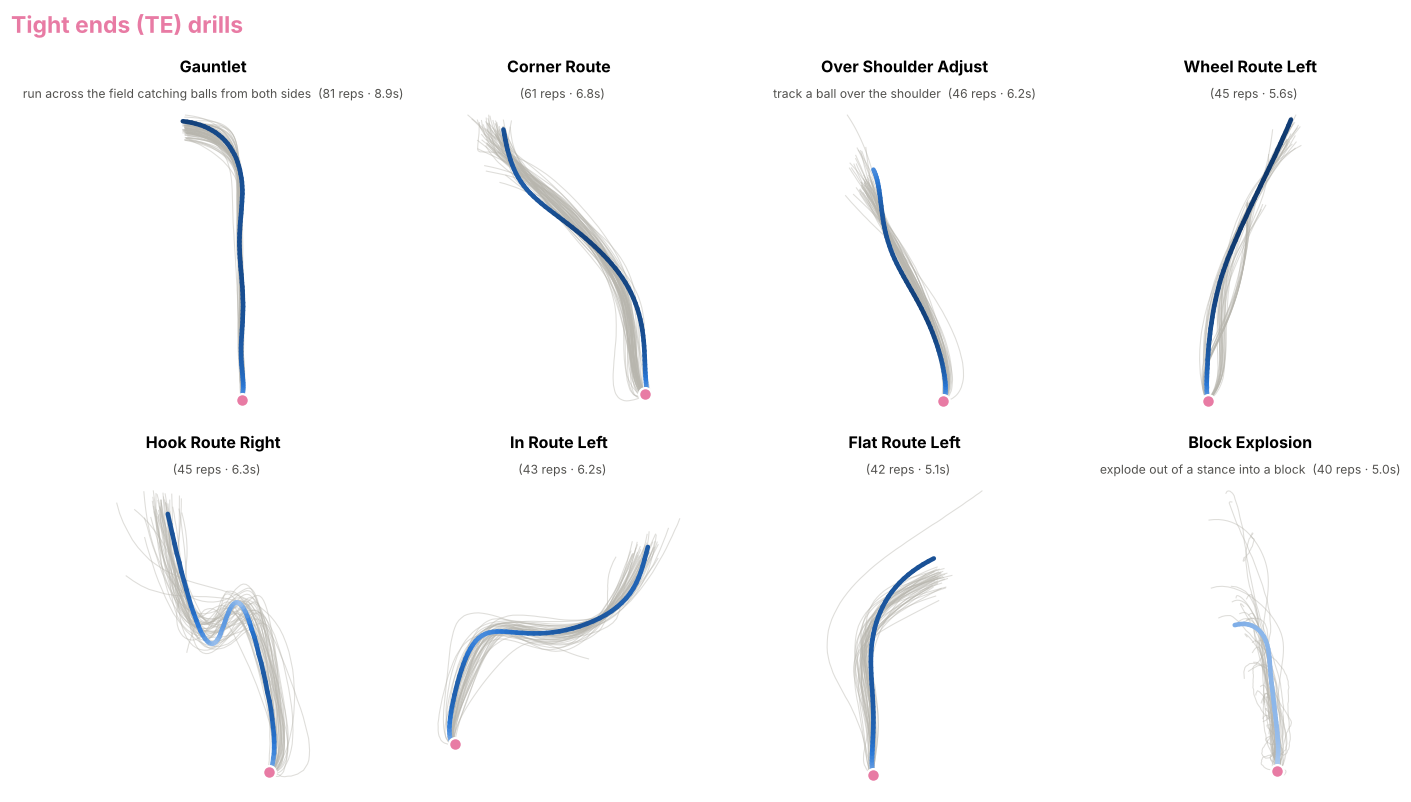

In [15]:
drill_gallery("TE")

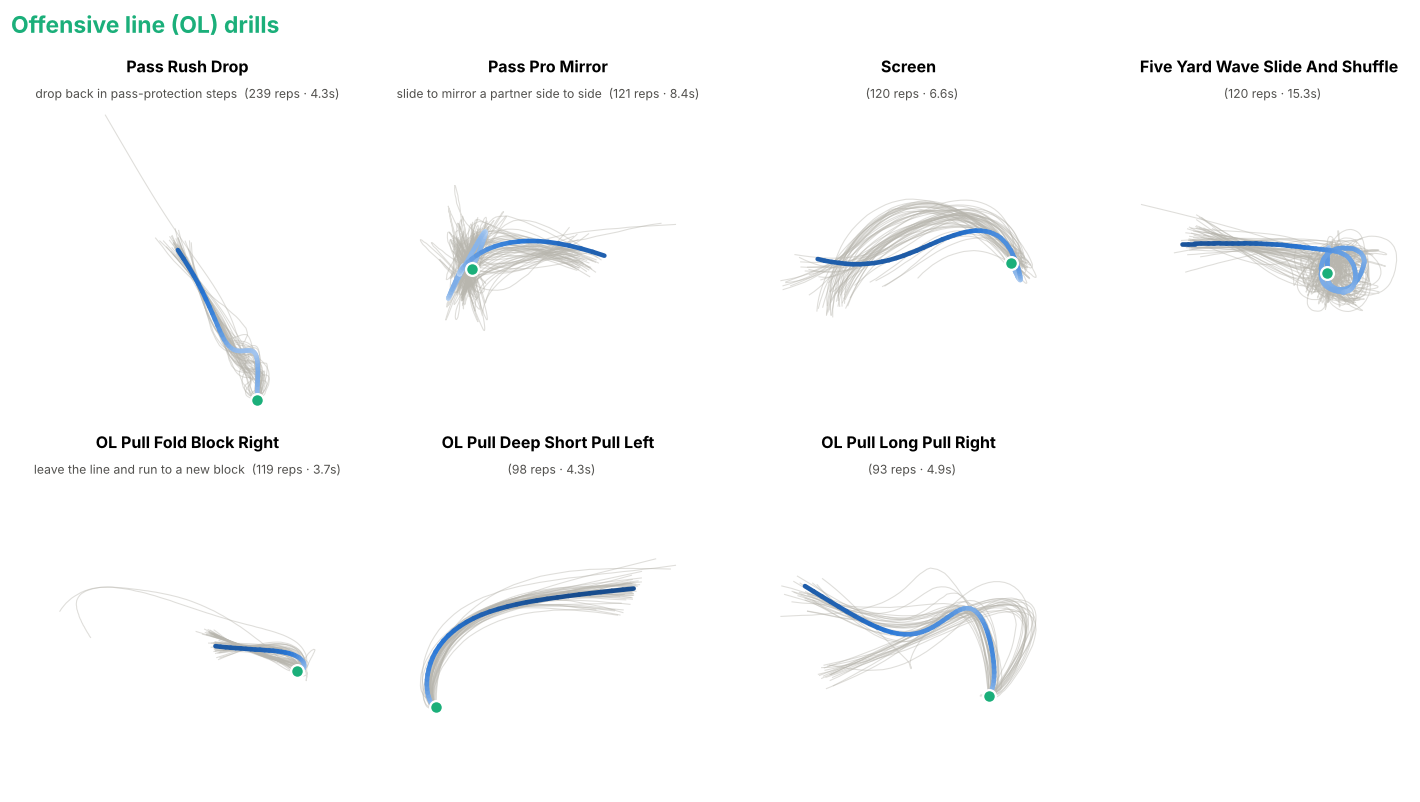

In [16]:
drill_gallery("OL")

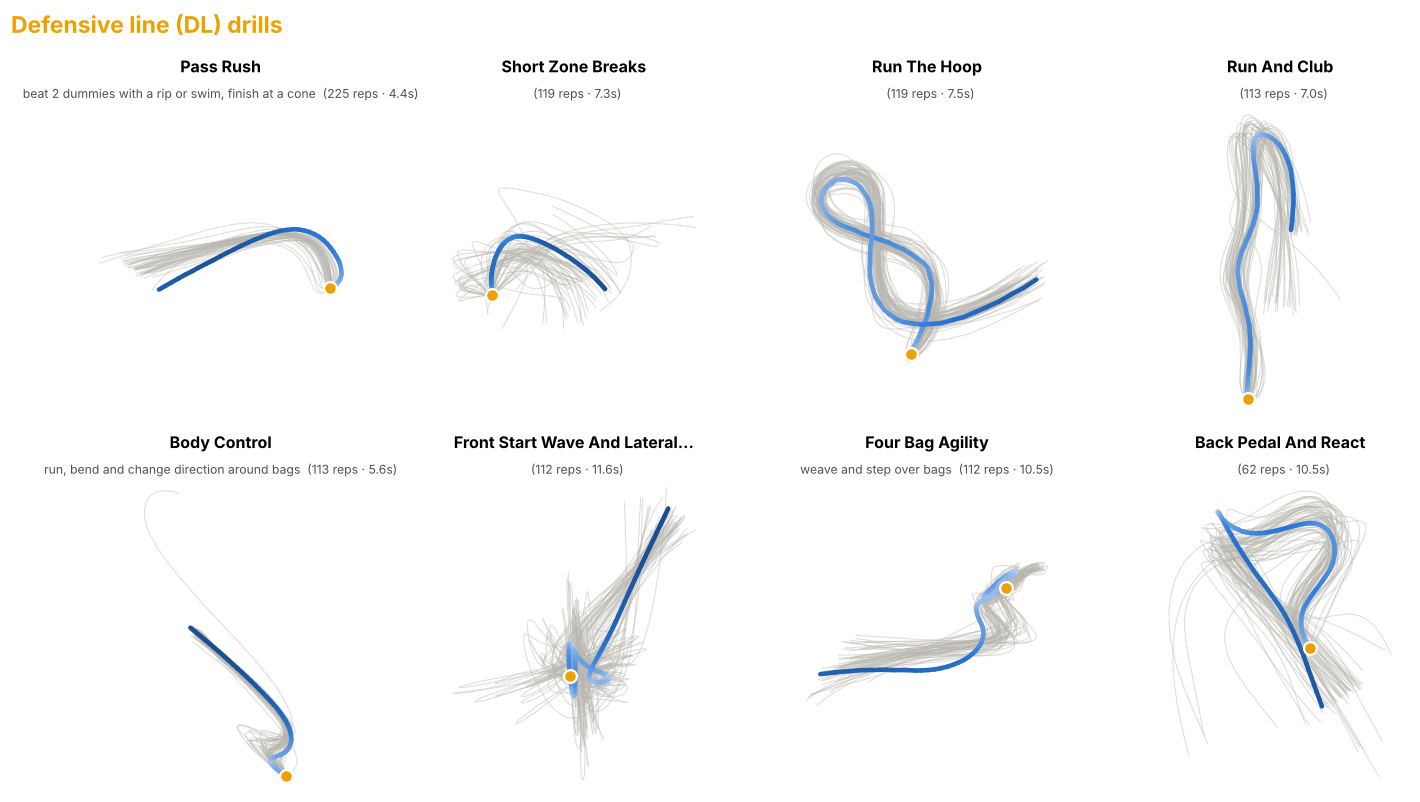

In [17]:
drill_gallery("DL")

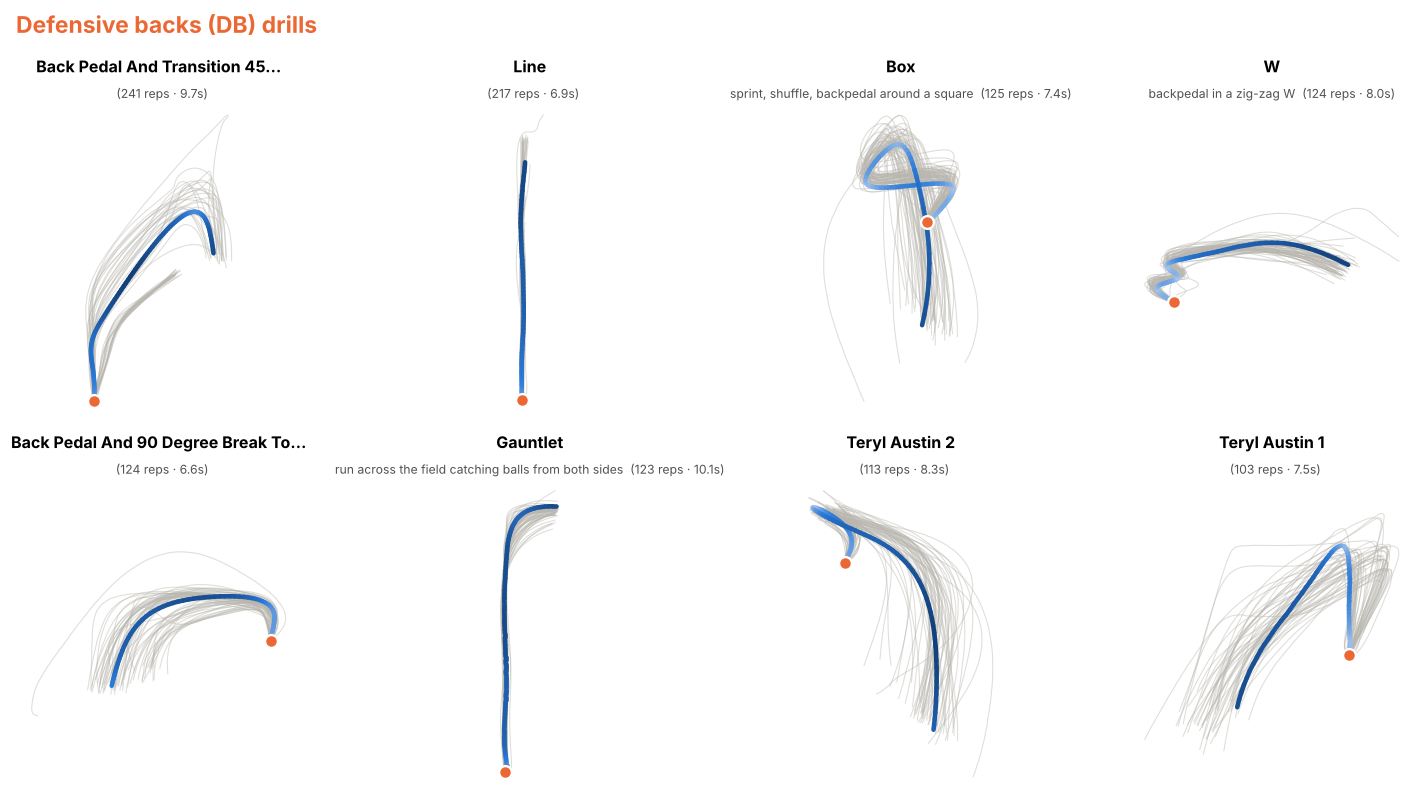

In [18]:
drill_gallery("DB")

> ⚠️ **Data notes for the Combine tracking**
> * Keep only `entity_type == "PLAYER"`: the WR/TE drills also have **BALL** rows that carry the receiver's `nfl_id`.
> * The Combine `dis` column is unreliable, so **recompute distance from x/y** (we did above).
> * Tracking starts with the player already moving: don't trust the first yards of the 40 to measure "burst".
> * 2024 `BACK_PEDAL_AND_TRANSITION_45` reps are cut off before the break. Treat them as missing.

---
## 5 · Sundays: the in-game data
For the same rookies we have their real NFL snaps: `player_play.csv` (one row per player per play, with stats like separation or pressure)
and `game_tracking_{2023,2024,2025}.csv` (the same 10 Hz tracking, during games).

### Same player, two worlds
Puka Nacua was a **5th-round pick** in 2023, then broke the NFL rookie records for catches and receiving yards.
On the left, his routes at the Combine; on the right, every route he ran in the 2023 regular season, grouped by type.

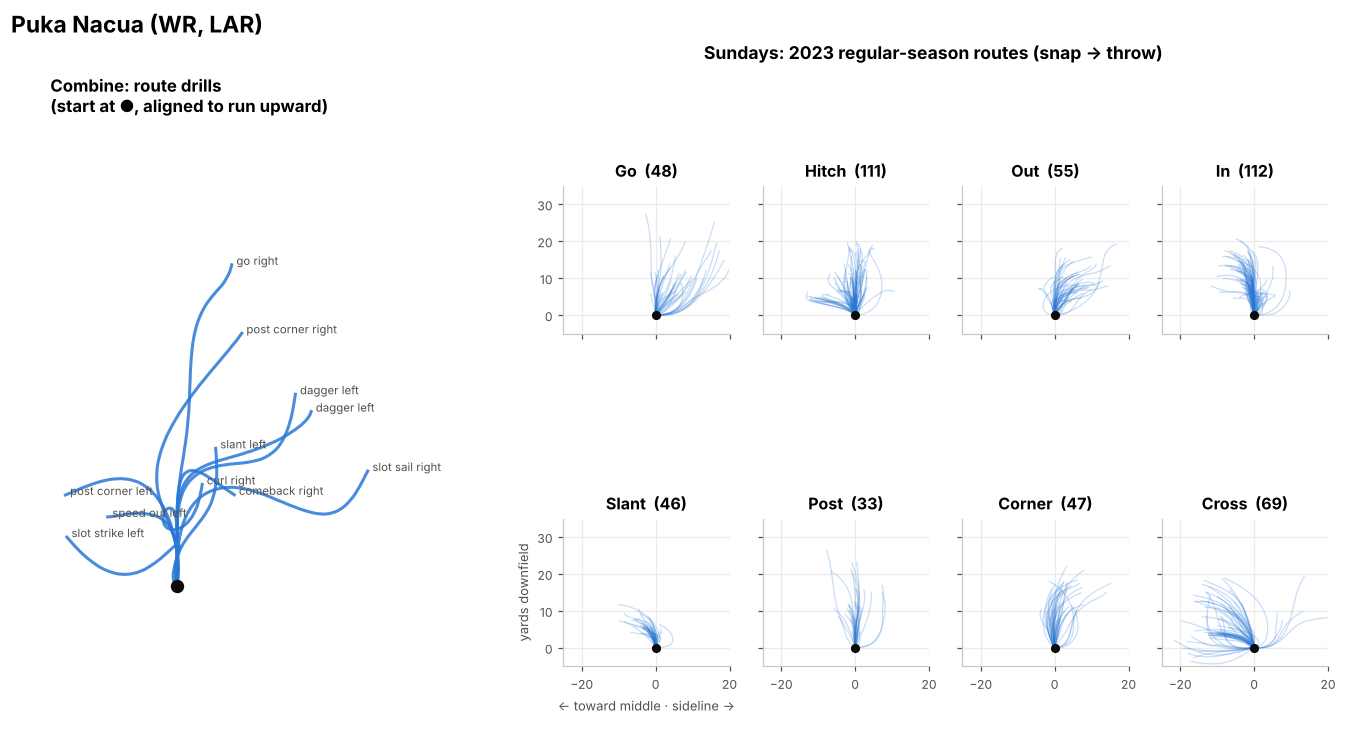

In [19]:
PUKA = 56042
gt23 = pl.scan_csv(DATA / "game_tracking_2023.csv", null_values="NA")

puka_plays = (player_play.filter((pl.col("nfl_id") == PUKA) & pl.col("route_ran").is_not_null())
              .join(games.filter(pl.col("season_type") == "REG"), on="game_id")
              .select("game_id", "play_id", "route_ran", "play_direction"))
puka = (gt23.filter(pl.col("nfl_id") == PUKA).collect()
        .join(puka_plays, on=["game_id", "play_id"])
        .sort("game_id", "play_id", "time")
        .with_columns(x=pl.when(pl.col("play_direction") == "left").then(120 - pl.col("x")).otherwise(pl.col("x")),
                      y=pl.when(pl.col("play_direction") == "left").then(53.3 - pl.col("y")).otherwise(pl.col("y")))
        .with_columns(snap=pl.col("event").eq("ball_snap").fill_null(False).cum_max().over("game_id", "play_id"),
                      fwd=pl.col("event").is_in(["pass_forward", "pass_shovel", "qb_sack", "run", "handoff"])
                      .fill_null(False).cum_max().over("game_id", "play_id"))
        .filter(pl.col("snap"))
        .with_columns(x0=pl.col("x").first().over("game_id", "play_id"), y0=pl.col("y").first().over("game_id", "play_id"),
                      ts=pl.int_range(pl.len()).over("game_id", "play_id") / 10)
        # route only: from the snap until the ball is thrown (max 4 s)
        .filter(~pl.col("fwd").shift(1).over("game_id", "play_id").fill_null(False) & (pl.col("ts") <= 4))
        .with_columns(dx=pl.col("x") - pl.col("x0"),
                      dy=pl.when(pl.col("y0") > 26.65).then(pl.col("y") - pl.col("y0")).otherwise(pl.col("y0") - pl.col("y"))))

ROUTES = ["GO", "HITCH", "OUT", "IN", "SLANT", "POST", "CORNER", "CROSS"]
fig = plt.figure(figsize=(13, 7.2))
sub = fig.subfigures(1, 2, width_ratios=[1, 2.3], wspace=0.02)
cax = sub[0].subplots(1, 1)
mine = tracking.filter((pl.col("nfl_id") == PUKA) & pl.col("drill_name").str.contains("ROUTE")).sort("event_id", "time")
for i, ((eid,), d) in enumerate(mine.group_by("event_id", maintain_order=True)):
    xy = rotate_to_first_move(d.select("x", "y").to_numpy())
    cax.plot(*xy.T, lw=2, color=POS_COLORS["WR"], alpha=0.85)
    cax.annotate(d["drill_name"][0].replace("_ROUTE", "").replace("_", " ").lower(), xy[-1], fontsize=7.5,
                 color=MUTED, xytext=(3, 0), textcoords="offset points")
cax.scatter(0, 0, s=60, color=INK, zorder=5)
cax.set_aspect("equal", adjustable="datalim")
cax.set_title("Combine: route drills\n(start at ●, aligned to run upward)", fontsize=11)
cax.set_xticks([])
cax.set_yticks([])
cax.grid(False)
cax.spines[["left", "bottom"]].set_visible(False)
axes = sub[1].subplots(2, 4, sharex=True, sharey=True)
for ax, r in zip(axes.ravel(), ROUTES):
    d = puka.filter(pl.col("route_ran") == r)
    for (_, _), p in d.group_by("game_id", "play_id"):
        ax.plot(p["dy"], p["dx"], color=POS_COLORS["WR"], lw=0.8, alpha=0.25)
    ax.scatter(0, 0, s=25, color=INK, zorder=5)
    ax.set_title(f"{r.title()}  ({d.select(pl.struct('game_id', 'play_id').n_unique()).item()})", fontsize=10.5, loc="center")
    ax.set_xlim(-25, 20)
    ax.set_ylim(-5, 35)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8)
axes[1, 0].set_xlabel("← toward middle · sideline →", fontsize=8.5)
axes[1, 0].set_ylabel("yards downfield", fontsize=8.5)
sub[1].suptitle("Sundays: 2023 regular-season routes (snap → throw)", fontsize=11.5, fontweight="bold")
fig.suptitle("Puka Nacua (WR, LAR)", x=0.01, ha="left", fontsize=15, fontweight="bold", y=1.02)
plt.show()

### What does "playing well" mean in the data?
Each group has its own stats in `player_play.csv`. Here are three of the most useful, one row per play.

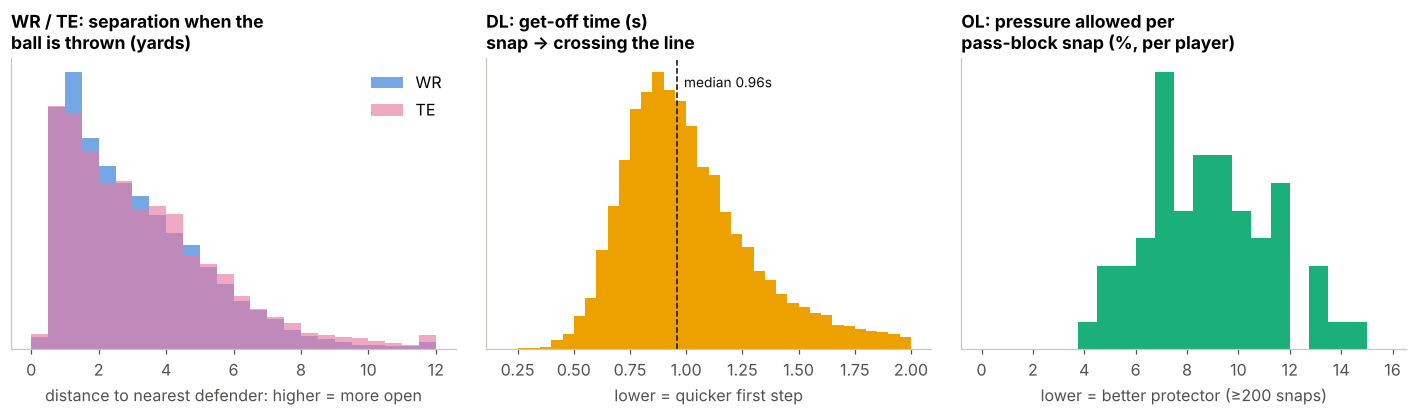

In [20]:
pp_reg = player_play.join(games.select("game_id", "season_type"), on="game_id").filter(pl.col("season_type") == "REG") \
    .join(combine.select("nfl_id", pos="combine_position"), on="nfl_id")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))

sep = pp_reg.filter(pl.col("pos").is_in(["WR", "TE"]) & pl.col("separation_at_pass_forward").is_not_null())
for p in ["WR", "TE"]:
    v = sep.filter(pl.col("pos") == p)["separation_at_pass_forward"].clip(0, 12).to_numpy()
    axes[0].hist(v, bins=np.arange(0, 12.5, 0.5), color=POS_COLORS[p], alpha=0.65, density=True, label=p)
axes[0].set_title("WR / TE: separation when the\nball is thrown (yards)", fontsize=11.5)
axes[0].set_xlabel("distance to nearest defender: higher = more open")
axes[0].legend()

go_off = pp_reg.filter((pl.col("pos") == "DL") & pl.col("player_get_off").is_not_null())["player_get_off"].to_numpy()
axes[1].hist(go_off, bins=np.arange(0.2, 2.05, 0.05), color=POS_COLORS["DL"])
axes[1].axvline(np.median(go_off), color=INK, ls="--", lw=1)
axes[1].text(np.median(go_off) + 0.03, axes[1].get_ylim()[1] * 0.9, f"median {np.median(go_off):.2f}s", color=INK, fontsize=9)
axes[1].set_title("DL: get-off time (s)\nsnap → crossing the line", fontsize=11.5)
axes[1].set_xlabel("lower = quicker first step")

ol = (pp_reg.filter((pl.col("pos") == "OL") & pl.col("pressure_allowed").is_not_null())
      .group_by("nfl_id").agg(rate=pl.col("pressure_allowed").cast(pl.Float64).mean() * 100, n=pl.len())
      .filter(pl.col("n") >= 200))
axes[2].hist(ol["rate"].to_numpy(), bins=np.arange(0, 16, 0.75), color=POS_COLORS["OL"])
axes[2].set_title("OL: pressure allowed per\npass-block snap (%, per player)", fontsize=11.5)
axes[2].set_xlabel("lower = better protector (≥200 snaps)")
for ax in axes:
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
plt.show()

> ⚠️ **Data notes for the game side**
> * Filter `season_type == "REG"`: `games.csv` also has preseason and playoff games.
> * Game tracking only has **these rookies**: no ball, no opponents, no QB. Standardise the direction (`play_direction`) before comparing plays.
> * WR/TE rows exist only on plays where they ran a route; there are no special-teams plays.
> * A 2025 rookie has 1 season of data, a 2023 rookie has 3. Compare *rates*, not career totals.

---
## 6 · Your first Combine → NFL link
Does Combine speed show up in games? Take each 2023 rookie's **top speed in the 40** and their **top speed in 2023 NFL games** (the 95th percentile of his per-play top speeds, so one sensor blip can't win).

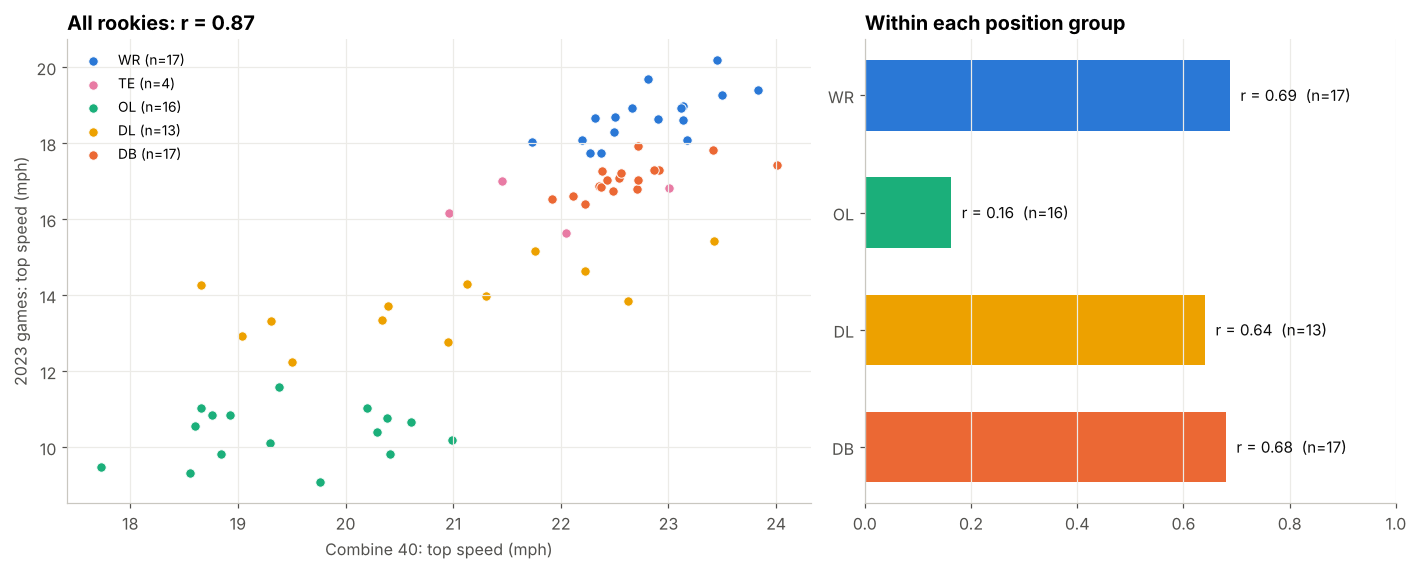

In [21]:
combine_top = (forty.group_by("nfl_id").agg(combine_top=pl.col("s").max() * YDS_TO_MPH))
game_top = (gt23.join(games.lazy().filter(pl.col("season_type") == "REG").select("game_id"), on="game_id")
            .group_by("nfl_id", "game_id", "play_id").agg(play_max=pl.col("s").max())        # fastest moment of each play
            .group_by("nfl_id").agg(game_top=pl.col("play_max").quantile(0.95) * YDS_TO_MPH,  # his fastest 5% of plays
                                    plays=pl.len())
            .filter(pl.col("plays") >= 100).collect())
link = (combine_top.join(game_top, on="nfl_id").join(combine.select("nfl_id", pos="combine_position"), on="nfl_id")
        .to_pandas())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for p in POS_ORDER:
    d = link[link.pos == p]
    ax.scatter(d.combine_top, d.game_top, s=38, color=POS_COLORS[p], edgecolor="white", lw=0.6, label=f"{p} (n={len(d)})")
r_all = np.corrcoef(link.combine_top, link.game_top)[0, 1]
ax.set_title(f"All rookies: r = {r_all:.2f}")
ax.set_xlabel("Combine 40: top speed (mph)")
ax.set_ylabel("2023 games: top speed (mph)")
ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
rs = [(p, np.corrcoef(*link[link.pos == p][["combine_top", "game_top"]].values.T)[0, 1], (link.pos == p).sum())
      for p in POS_ORDER if (link.pos == p).sum() >= 8]          # skip groups too small to say anything
for i, (p, r, n_) in enumerate(rs):
    ax.barh(len(rs) - 1 - i, r, color=POS_COLORS[p], height=0.6)
    ax.text(r + 0.02, len(rs) - 1 - i, f"r = {r:.2f}  (n={n_})", va="center", color=INK, fontsize=10)
ax.set_yticks(range(len(rs)), [p for p, *_ in rs][::-1])
ax.set_xlim(0, 1)
ax.set_title("Within each position group")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**What this tells you:** nobody runs as fast in a game as in a straight 40 (football is turns, traffic and stops).
Across all rookies, Combine speed and game speed line up well, but much of that is just *position* (linemen are slower than receivers).
**Inside** a position group, the link is weaker. That's the real game in this competition: find signal *within* a group, about something that **wins plays**, not just "fast guys are fast".

---
## 🧭 Where to go next

The hosts suggest going **narrow**: one movement, one position group, one drill. A few starting ideas:

| Idea | Combine side | Sunday side |
|---|---|---|
| **Cuts → open receivers** | how fast a WR slows down and re-accelerates in route drills | `separation_at_pass_forward` |
| **First step → pressure** | DL acceleration off the line in the pass-rush drill | `player_get_off`, `time_to_pressure` |
| **Mirror → protection** | OL lateral quickness in the mirror drill | `pressure_allowed` |
| **Hips → coverage** | DB transition time in backpedal-and-break drills | in-game tracking on coverage snaps |

### ✅ Checklist before you trust a result
1. `entity_type == "PLAYER"` and normalised drill names
2. Distance recomputed from x/y; the first frames of the 40 aren't a clean start
3. `season_type == "REG"` and per-snap **rates**, not career totals
4. Compare **within** a position group, and account for draft slot (teams already know who's fast)
5. Small samples: ~100 players per group. Show uncertainty

### 📖 Mini glossary
**Snap**: the moment the play starts · **Down**: one attempt · **LOS**: line of scrimmage · **Route**: the path a receiver runs ·
**Separation**: distance from receiver to nearest defender · **Pressure**: a defender forces the QB to hurry · **Sack**: QB tackled behind the LOS ·
**UDFA**: undrafted free agent · **10 Hz**: 10 samples per second

*If this helped you get started, an upvote helps others find it. Good luck in the Big Data Bowl! 🏈*